In [2]:
import pandas as pd
import yfinance as yf
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt

## Regression

Regression  - predicting output using input
            - predicting Y using X

    Linear Regression       - straight line relationship
    Polynomial Regression   - curved line relationship
    Multiple Regression     - multiple X variables
    Logistic Regression     - predict yes/no


In [3]:
gbpaud = yf.download("GBPAUD=X", period="10y")[["Close"]]
euraud = yf.download("EURAUD=X", period="10y")[["Close"]]

gbpaud.columns = ["GBPAUD"]
euraud.columns = ["EURAUD"]

gbpaud_returns = gbpaud["GBPAUD"].pct_change(fill_method=None)
euraud_returns = euraud["EURAUD"].pct_change(fill_method=None)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


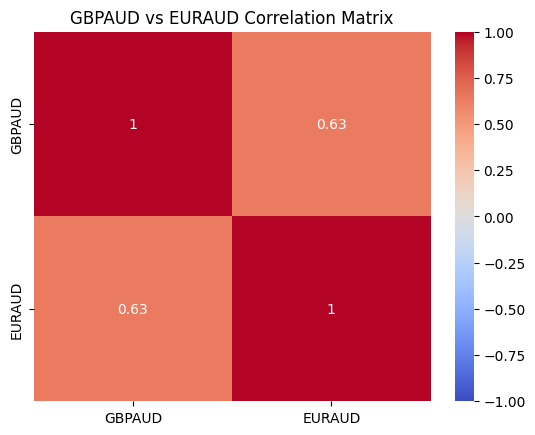

In [12]:
df = pd.concat([gbpaud_returns, euraud_returns], axis=1)
df.columns = ["GBPAUD", "EURAUD"]

df = df.dropna()

sns.heatmap(df.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("GBPAUD vs EURAUD Correlation Matrix")
plt.show()

In [5]:
slope, intercept, r_value, p_value, std_err = stats.linregress(
    df["GBPAUD"],
    df["EURAUD"]
)

print(f"Slope       : {slope:.5f}")
print(f"Intercept   : {intercept:.5f}")
print(f"R-squared   : {r_value**2:.5f}")
print(f"P-value     : {p_value:.5f}")

Slope       : 0.58487
Intercept   : 0.00003
R-squared   : 0.40301
P-value     : 0.00000


    Slope(Coefficient)  - How much Y moves when X moves by 1        - To check relantionship
    Intercept           - Value of Y when X is 0                    - Baseline Value
    R-squared           - The weightage of X affecting Y            - How much X can explain Y moves
    P-value             - To check regression result worthy or not  

In [7]:
X = sm.add_constant(df["GBPAUD"])
Y = df["EURAUD"]

model = sm.OLS(Y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 EURAUD   R-squared:                       0.403
Model:                            OLS   Adj. R-squared:                  0.403
Method:                 Least Squares   F-statistic:                     1755.
Date:                Fri, 15 May 2026   Prob (F-statistic):          1.81e-293
Time:                        05:01:04   Log-Likelihood:                 10746.
No. Observations:                2601   AIC:                        -2.149e+04
Df Residuals:                    2599   BIC:                        -2.148e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       3.234e-05   7.62e-05      0.424      0.6

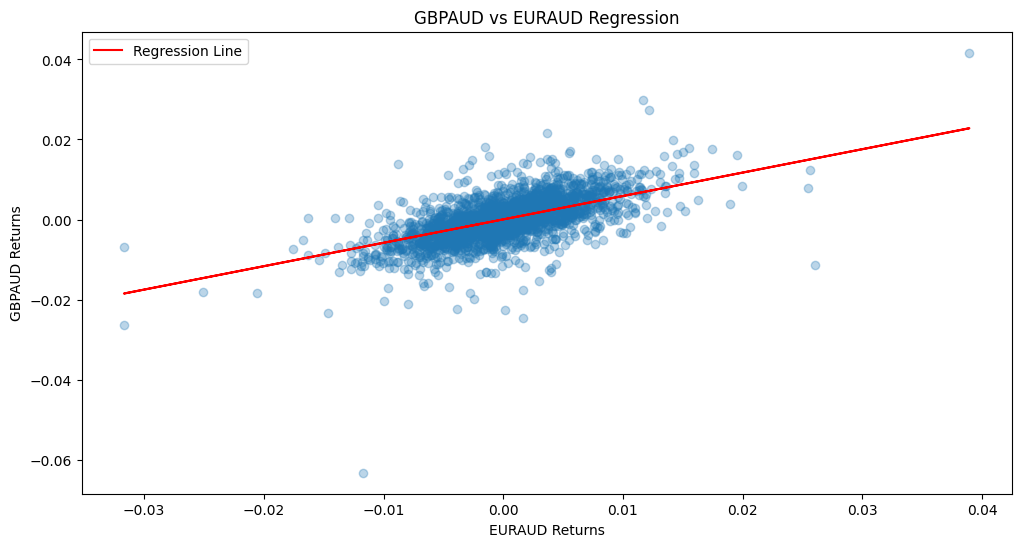

In [10]:
plt.figure(figsize=(12,6))
plt.scatter(df["EURAUD"], df["GBPAUD"], alpha=0.3)
plt.plot(df["EURAUD"], slope * df["EURAUD"] + intercept,
         color="red", label="Regression Line")
plt.xlabel("EURAUD Returns")
plt.ylabel("GBPAUD Returns")
plt.title("GBPAUD vs EURAUD Regression")
plt.legend()
plt.show()

    Slope Direction - Positive      - Y follows X
                    - Negative      - Y inverse X
                    - Flat Line     - No relationship (slope = 0)

    Scatter with Line   - High R-squared - dots close to line
                        - Low R-squared  - dots far from line